# Практическая работа № 10. Кластеризация и сегментация клиентов

**Цель:** выбрать число кластеров несколькими критериями, описать сегменты и проверить устойчивость кластеризации.

Используется Telco Customer Churn. `customerID` не является характеристикой клиента, а `Churn` не участвует в обучении кластеров; доля оттока используется только после кластеризации для интерпретации сегментов.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
SILHOUETTE_SAMPLE_SIZE = 2000
DATA_CANDIDATES = [Path("data/raw/Churn.csv"), Path("../data/raw/Churn.csv"), Path("../../data/raw/Churn.csv")]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Не найден data/raw/Churn.csv. Запустите ноутбук из корня репозитория или notebooks/practice_10.")

df = pd.read_csv(DATA_PATH)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

target_column = "Churn"
id_column = "customerID"
feature_df = df.drop(columns=[target_column, id_column]).copy()
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_columns = [column for column in feature_df.columns if column not in numeric_columns]
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), categorical_columns),
], verbose_feature_names_out=False)
X_scaled = preprocessor.fit_transform(feature_df)
feature_names = preprocessor.get_feature_names_out()
print(f"Объектов: {len(df)}; признаков до кодирования: {feature_df.shape[1]}; после кодирования: {X_scaled.shape[1]}")
print(f"Числовые признаки стандартизированы: {numeric_columns}")
print("Целевой признак Churn исключён из кластеризации.")

Объектов: 7043; признаков до кодирования: 19; после кодирования: 40
Числовые признаки стандартизированы: ['tenure', 'MonthlyCharges', 'TotalCharges']
Целевой признак Churn исключён из кластеризации.


## 1. Метод локтя и силуэт

Для `k=2..10` вычисляются инерция K-means и silhouette score. Инерция рассчитывается по всем объектам. Силуэт использует одну и ту же случайную подвыборку из 2 000 объектов для каждого k, чтобы ускорить расчёт и сделать сравнение значений сопоставимым; seed подвыборки фиксирован.

In [2]:
k_values = range(2, 11)
selection_rows = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    silhouette = silhouette_score(
        X_scaled, labels, sample_size=min(SILHOUETTE_SAMPLE_SIZE, len(X_scaled)),
        random_state=RANDOM_STATE,
    )
    selection_rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette})
selection = pd.DataFrame(selection_rows)
display(selection.round(4))

,k,inertia,silhouette
0,2,55676.6516,0.2741
1,3,42832.3962,0.2759
2,4,39264.1661,0.2272
3,5,36971.3688,0.2102
4,6,35270.7057,0.1731
5,7,33850.9700,0.1541
6,8,32825.4107,0.1380
7,9,31965.9983,0.1348
8,10,31198.8776,0.1352


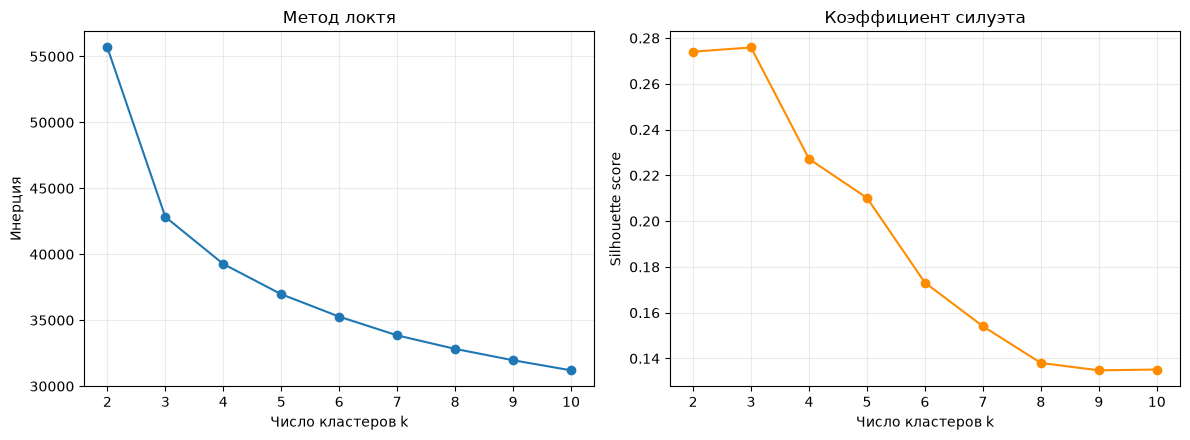

Максимальный силуэт при k = 3


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(selection["k"], selection["inertia"], marker="o")
axes[0].set(title="Метод локтя", xlabel="Число кластеров k", ylabel="Инерция")
axes[0].set_xticks(list(k_values)); axes[0].grid(alpha=0.25)
axes[1].plot(selection["k"], selection["silhouette"], marker="o", color="darkorange")
axes[1].set(title="Коэффициент силуэта", xlabel="Число кластеров k", ylabel="Silhouette score")
axes[1].set_xticks(list(k_values)); axes[1].grid(alpha=0.25)
fig.tight_layout(); plt.show()
print("Максимальный силуэт при k =", int(selection.loc[selection["silhouette"].idxmax(), "k"]))

## 2. Итоговое число кластеров и профили

Сопоставьте замедление снижения инерции с максимумом силуэта. Максимальный силуэт не является единственным правилом: итоговое k должно давать сегменты, которые можно описать и использовать на практике.

Ниже профили строятся для числовых средних, наиболее частых категорий и доли оттока в каждом кластере. `Churn` здесь служит только для постфактум-интерпретации.

In [4]:
# Укажите итоговое k после просмотра обеих кривых.
FINAL_K = 3
final_model = KMeans(n_clusters=FINAL_K, n_init=20, random_state=RANDOM_STATE)
labels_42 = final_model.fit_predict(X_scaled)
clustered = df.copy()
clustered["cluster"] = labels_42
CLUSTER_NAMES = {
    0: "Лояльные клиенты с долгим стажем и расширенными услугами",
    1: "Экономные клиенты без интернета, с низким оттоком",
    2: "Новые клиенты на помесячном контракте, группа риска оттока",
}

profile_rows = []
for cluster_id, group in clustered.groupby("cluster", sort=True):
    row = {
        "cluster": int(cluster_id),
        "segment_name": CLUSTER_NAMES[int(cluster_id)],
        "size": len(group),
        "share": len(group) / len(clustered),
        "tenure_mean": group["tenure"].mean(),
        "MonthlyCharges_mean": group["MonthlyCharges"].mean(),
        "TotalCharges_mean": group["TotalCharges"].mean(),
        "SeniorCitizen_rate": group["SeniorCitizen"].mean(),
        "Churn_rate": (group["Churn"] == "Yes").mean(),
    }
    for column in categorical_columns:
        row[f"{column}_mode"] = group[column].mode(dropna=False).iloc[0]
    profile_rows.append(row)
profiles = pd.DataFrame(profile_rows).set_index("cluster")
display(profiles.round(3))
print("Кластерные размеры:", clustered["cluster"].value_counts().sort_index().to_dict())

,segment_name,size,share,tenure_mean,MonthlyCharges_mean,TotalCharges_mean,SeniorCitizen_rate,Churn_rate,gender_mode,SeniorCitizen_mode,...,InternetService_mode,OnlineSecurity_mode,OnlineBackup_mode,DeviceProtection_mode,TechSupport_mode,StreamingTV_mode,StreamingMovies_mode,Contract_mode,PaperlessBilling_mode,PaymentMethod_mode
cluster,,,,,,,,,,,,,,,,,,,,,
0,Лояльные клиенты с долгим стажем и расширенным...,2325,0.330,57.040,89.134,5074.003,0.200,0.150,Male,0,...,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic)
1,"Экономные клиенты без интернета, с низким оттоком",1526,0.217,30.547,21.079,668.099,0.034,0.074,Male,0,...,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check
2,"Новые клиенты на помесячном контракте, группа ...",3192,0.453,15.275,67.893,1019.726,0.196,0.441,Male,0,...,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check


Кластерные размеры: {0: 2325, 1: 1526, 2: 3192}


## 3. Проверка устойчивости

Повторяем K-means с тем же k, но другим `random_state`. Adjusted Rand Index (ARI) сравнивает разбиения без зависимости от номеров кластеров: 1 означает совпадающее распределение объектов, около 0 — сходство на уровне случайного разбиения. Таблица пересечения помогает увидеть, какие сегменты перемешались.

In [5]:
stability_model = KMeans(n_clusters=FINAL_K, n_init=20, random_state=7)
labels_7 = stability_model.fit_predict(X_scaled)
ari = adjusted_rand_score(labels_42, labels_7)
cross_tab = pd.crosstab(pd.Series(labels_42, name="random_state=42"), pd.Series(labels_7, name="random_state=7"))
print(f"Adjusted Rand Index = {ari:.4f}")
print("Состав кластеров практически тот же." if ari >= 0.95 else "Состав кластеров изменился; интерпретируйте сегменты с осторожностью.")
display(cross_tab)
stability_sizes = pd.DataFrame({
    "random_state=42": pd.Series(labels_42).value_counts().sort_index(),
    "random_state=7": pd.Series(labels_7).value_counts().sort_index(),
})
display(stability_sizes)

Adjusted Rand Index = 1.0000
Состав кластеров практически тот же.


random_state=7,0,1,2
random_state=42,,,
0,0,2325,0
1,1526,0,0
2,0,0,3192


,random_state=42,random_state=7
0,2325,1526
1,1526,2325
2,3192,3192


## 4. Содержательная интерпретация и вывод

**Выбор k=3.** Инерция снижается с 55 676.65 при k=2 до 42 832.40 при k=3, затем снижение замедляется (до 39 264.17 при k=4), что указывает на локоть около k=3. Максимум силуэта также при k=3: **0.2759**; для k=2 он почти такой же (**0.2741**), а начиная с k=4 силуэт падает. Поэтому k=3 даёт разумный баланс компактности, качества разделения и понятного числа сегментов. Невысокий абсолютный силуэт говорит, что границы сегментов не идеальны и клиенты частично похожи друг на друга.

**Сегменты по профилям:**

1. **Лояльные клиенты с долгим стажем и расширенными услугами** — 2 325 клиентов (33.0%); средний стаж 57.0 мес., расходы 89.13 в месяц, доля оттока 15.0%. Типичный клиент имеет двухлетний контракт и использует несколько дополнительных интернет-услуг.
2. **Экономные клиенты без интернета, с низким оттоком** — 1 526 (21.7%); средний стаж 30.5 мес., расходы 21.08 в месяц, доля оттока 7.4%. Типичный контракт двухлетний; интернет-услуги не подключены.
3. **Новые клиенты на помесячном контракте, группа риска оттока** — 3 192 (45.3%); средний стаж 15.3 мес., расходы 67.89 в месяц, доля оттока 44.1%. Типичный договор помесячный, часто Fiber optic без дополнительных защитных услуг.

**Устойчивость.** При повторном запуске с `random_state=7` Adjusted Rand Index = **1.0000**. Разбиение объектов совпало полностью; изменились лишь номера кластеров, что видно по таблице пересечений.

Доля оттока и целевой столбец не участвовали в обучении кластеров — они использованы только для содержательной оценки уже найденных сегментов.